#### CSV limpio

In [2]:
from pathlib import Path
import pandas as pd

ruta = Path("data/processed/viral_songs_limpio.csv")
if not ruta.exists():
    ruta = Path("../data/processed/viral_songs_limpio.csv")

df = pd.read_csv(ruta)

print(df.shape)
print(df["viral"].value_counts())

(10000, 16)
viral
0    6395
1    3605
Name: count, dtype: int64


#### Selección de variables y división de datos

In [3]:
from sklearn.model_selection import train_test_split

numericas = [
    "release_year", "duration_sec", "danceability", "energy", "valence",
    "tempo_bpm", "acousticness", "instrumentalness", "speechiness",
    "liveness", "loudness_db", "streams",
]

num_features = [col for col in numericas if col != "streams"]
cat_features = ["genre"]

X = df[num_features + cat_features]
y = df["viral"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_test.value_counts())

(8000, 12) (2000, 12)
viral
0    1279
1     721
Name: count, dtype: int64


X contiene las 12 variables predictoras de cada canción: 11 numéricas y genre. Se excluyen streams y track_id. y es la variable objetivo viral (0 = no viral, 1 = viral). Los datos se dividieron en entrenamiento (8.000 canciones) y prueba (2.000), conservando la proporción de ambas clases.

#### Procesamiento de variables

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocesador = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

#### Comparación de modelos mediante validación cruzada

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

modelos = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Regresión logística": Pipeline([
        ("preprocesador", preprocesador),
        ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ]),
}

metricas = ["balanced_accuracy", "precision", "recall", "f1", "roc_auc"]

for nombre, modelo in modelos.items():
    resultados = cross_validate(
        modelo, X_train, y_train, cv=cv, scoring=metricas
    )
    print(f"\n{nombre}")
    for metrica in metricas:
        valores = resultados[f"test_{metrica}"]
        print(f"{metrica}: {valores.mean():.3f} ± {valores.std():.3f}")

c:\Users\maiya\.codex\proyecto_profundizacion\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\maiya\.codex\proyecto_profundizacion\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\maiya\.codex\proyecto_profundizacion\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capital


Dummy
balanced_accuracy: 0.500 ± 0.000
precision: 0.000 ± 0.000
recall: 0.000 ± 0.000
f1: 0.000 ± 0.000
roc_auc: 0.500 ± 0.000

Regresión logística
balanced_accuracy: 0.725 ± 0.007
precision: 0.568 ± 0.002
recall: 0.786 ± 0.023
f1: 0.659 ± 0.008
roc_auc: 0.792 ± 0.010


Este código compara un DummyClassifier con una regresión logística mediante validación cruzada estratificada de cinco pliegues sobre los datos de entrenamiento. Calcula balanced accuracy, precisión, recall, F1 y ROC-AUC para medir y comparar el desempeño de ambos modelos.

La regresión logística superó al Dummy en validación cruzada. Obtuvo una balanced accuracy de 0,725 y un ROC-AUC de 0,792, frente a 0,500 en ambos casos para el Dummy. Su recall fue 0,786, aunque su precisión fue 0,568. La baja variación entre pliegues indica resultados consistentes. El Dummy no identificó canciones virales porque siempre predijo la clase mayoritaria.


#### Evaluación final del modelo en el conjunto de prueba

Balanced accuracy: 0.731
ROC-AUC: 0.808
              precision    recall  f1-score   support

    No viral       0.85      0.68      0.76      1279
       Viral       0.58      0.78      0.67       721

    accuracy                           0.72      2000
   macro avg       0.71      0.73      0.71      2000
weighted avg       0.75      0.72      0.72      2000



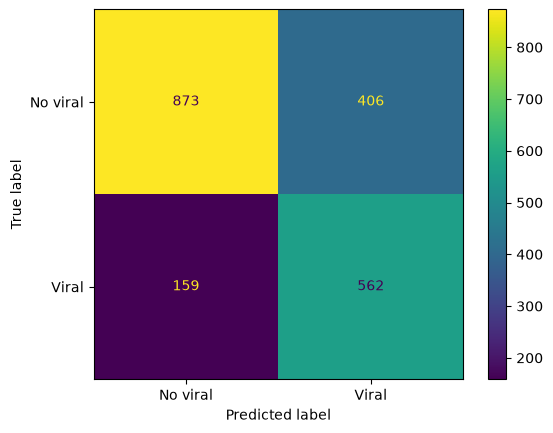

In [ ]:
from sklearn.metrics import (
    balanced_accuracy_score,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
)

modelo_final = modelos["Regresión logística"]
modelo_final.fit(X_train, y_train)

y_pred = modelo_final.predict(X_test)
y_proba = modelo_final.predict_proba(X_test)[:, 1]

print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 3))
print(classification_report(
    y_test, y_pred, target_names=["No viral", "Viral"], zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["No viral", "Viral"]
)

En el conjunto de prueba, la regresión logística obtuvo una balanced accuracy de 0,731 y un ROC-AUC de 0,808. Para las canciones virales, alcanzó una precisión de 0,58 y un recall de 0,78: detectó la mayoría de las virales, aunque también clasificó algunas canciones no virales como virales. La accuracy global fue 0,72. La evaluación incluyó 2.000 canciones: 1.279 no virales y 721 virales.

#### KPI de negocio: viralidad entre las primeras 100 recomendaciones

In [ ]:
import pandas as pd

k = 100  # Confirma con el equipo que 100 sea el cupo de revisión
ranking = pd.DataFrame({
    "viral_real": y_test.to_numpy(),
    "probabilidad_viral": y_proba,
})

top_k = ranking.nlargest(k, "probabilidad_viral")
tasa_top_k = top_k["viral_real"].mean()
tasa_global = y_test.mean()

print(f"Virales entre las primeras {k}: {top_k['viral_real'].sum()} ({tasa_top_k:.1%})")
print(f"Tasa global en prueba: {tasa_global:.1%}")
print(f"Esperadas al azar entre {k}: {tasa_global * k:.1f}")

Virales entre las primeras 100: 79 (79.0%)
Tasa global en prueba: 36.0%
Esperadas al azar entre 100: 36.0


79 de las primeras 100 canciones fueron virales (79 %). Con una selección al azar, se esperarían alrededor de 36. La priorización encontró 43 canciones virales más por cada 100 revisadas en este conjunto de prueba. Confirma con el equipo que 100 sea el cupo de revisión que quieren usar.